# E02 · 车道线检测 V2.0

## 00 · 环境与素材
Hough 候选线段不是人工 Ground Truth，候选数不能当作准确率。

In [1]:

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
def locate_images():
    here=Path.cwd().resolve()
    for root in [here,*here.parents]:
        p=root/'images'
        if (p/'01_solidWhiteRight_straight_white.jpg').exists(): return p
    kaggle=Path('/kaggle/input')
    if kaggle.exists():
        for p in kaggle.glob('**/images/01_solidWhiteRight_straight_white.jpg'): return p.parent
    raise FileNotFoundError('请解压完整教学包，确保 images/ 与 Notebook 一同提供')
IMAGES=locate_images()
def read(name):
    x=cv2.imread(str(IMAGES/name))
    if x is None: raise FileNotFoundError(name)
    return x
def view(items):
    fig,axs=plt.subplots(1,len(items),figsize=(5*len(items),4))
    if len(items)==1: axs=[axs]
    for ax,(name,img) in zip(axs,items):
        ax.imshow(img if img.ndim==2 else cv2.cvtColor(img,cv2.COLOR_BGR2RGB),cmap='gray' if img.ndim==2 else None)
        ax.set_title(name);ax.axis('off')
    plt.tight_layout();plt.show()
print('Image path:',IMAGES,'OpenCV:',cv2.__version__)


Image path: /home/runner/work/multimodal-document-ai-learning-center/multimodal-document-ai-learning-center/docs/resources/course-labs/intelligent-perception/images OpenCV: 5.1.0


## 01 · Canny 阈值
边缘越多越好吗？

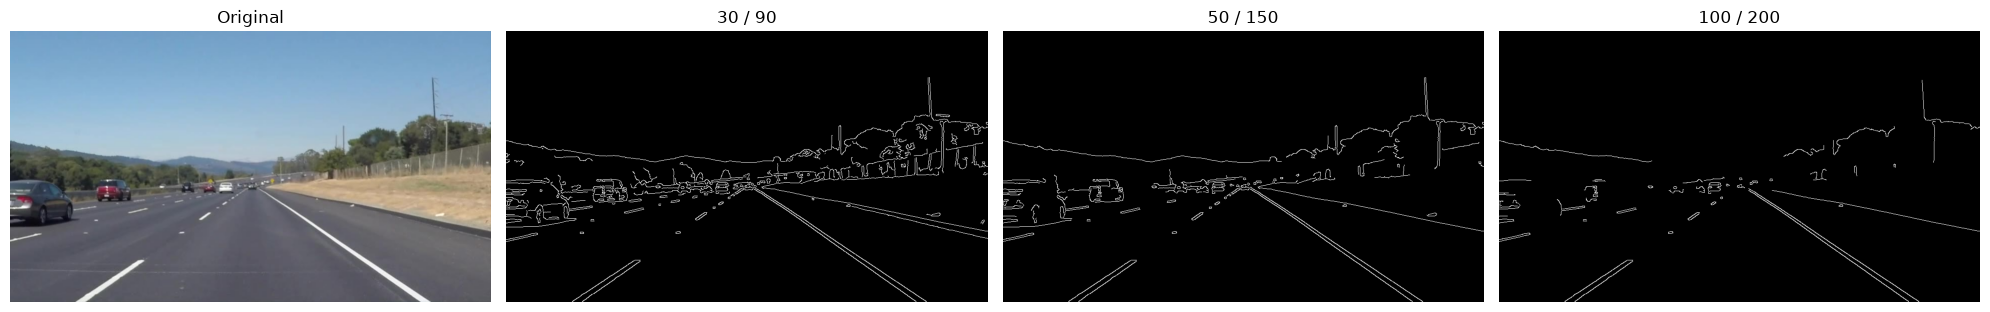

In [2]:
img=read('01_solidWhiteRight_straight_white.jpg')
blur=cv2.GaussianBlur(cv2.cvtColor(img,cv2.COLOR_BGR2GRAY),(5,5),1.2)
view([('Original',img),('30 / 90',cv2.Canny(blur,30,90)),
('50 / 150',cv2.Canny(blur,50,150)),('100 / 200',cv2.Canny(blur,100,200))])

## 02 · ROI + Hough
修改 ROI 梯形顶部比例与 Hough 参数。

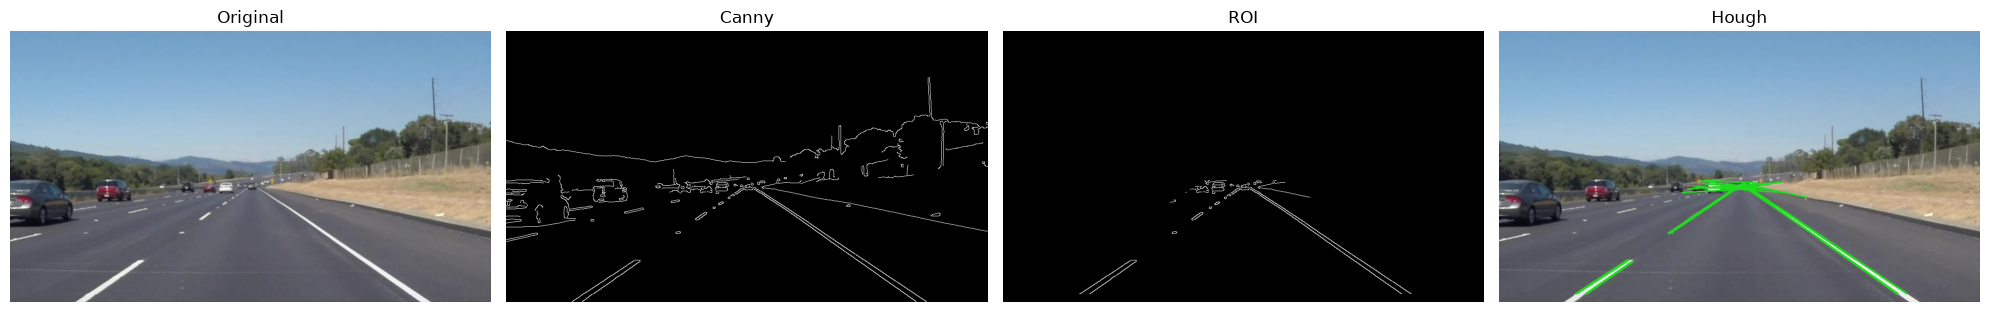

Hough candidates: 24


In [3]:
def pipeline(img,top=.55,lo=50,hi=150,votes=25,length=35,gap=70):
    h,w=img.shape[:2]
    gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    edges=cv2.Canny(cv2.GaussianBlur(gray,(5,5),1.2),lo,hi)
    mask=np.zeros((h,w),np.uint8)
    poly=np.array([[(int(.05*w),int(.97*h)),(int(.42*w),int(top*h)),
                    (int(.58*w),int(top*h)),(int(.98*w),int(.97*h))]],np.int32)
    cv2.fillPoly(mask,poly,255)
    roi=cv2.bitwise_and(edges,mask)
    result=img.copy()
    lines=cv2.HoughLinesP(roi,1,np.pi/180,threshold=votes,minLineLength=length,maxLineGap=gap)
    found=[] if lines is None else np.asarray(lines).reshape(-1,4).tolist()
    for x1,y1,x2,y2 in found:
        cv2.line(result,(x1,y1),(x2,y2),(30,220,30),2)
    return edges,roi,result,found
img=read('01_solidWhiteRight_straight_white.jpg')
edge,roi,overlay,lines=pipeline(img)
view([('Original',img),('Canny',edge),('ROI',roi),('Hough',overlay)])
print('Hough candidates:',len(lines))

## 03 · 左右候选线筛选
根据斜率区分左右候选线，但没有语义识别能力。

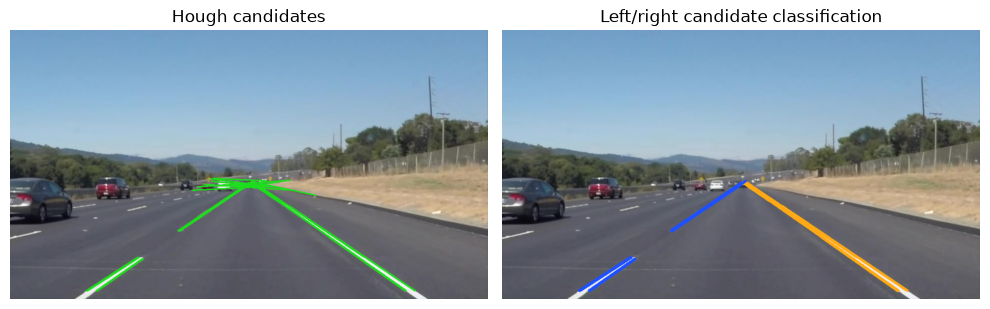

In [4]:
img=read('01_solidWhiteRight_straight_white.jpg')
_,_,all_lines,lines=pipeline(img)
h,w=img.shape[:2]
left_right=img.copy()
for x1,y1,x2,y2 in lines:
    if abs(y2-y1)<5: continue
    slope=(x2-x1)/(y2-y1)
    if abs(slope)<.45: continue
    xb=x1+slope*(.97*h-y1)
    if slope<0 and .03*w<xb<.5*w: color=(255,80,30)
    elif slope>0 and .5*w<xb<.97*w: color=(20,170,255)
    else: continue
    cv2.line(left_right,(x1,y1),(x2,y2),color,4)
view([('Hough candidates',all_lines),('Left/right candidate classification',left_right)])

## 04 · 固定参数九图泛化
不针对每张图片单独调参，寻找误检和漏检的原因。

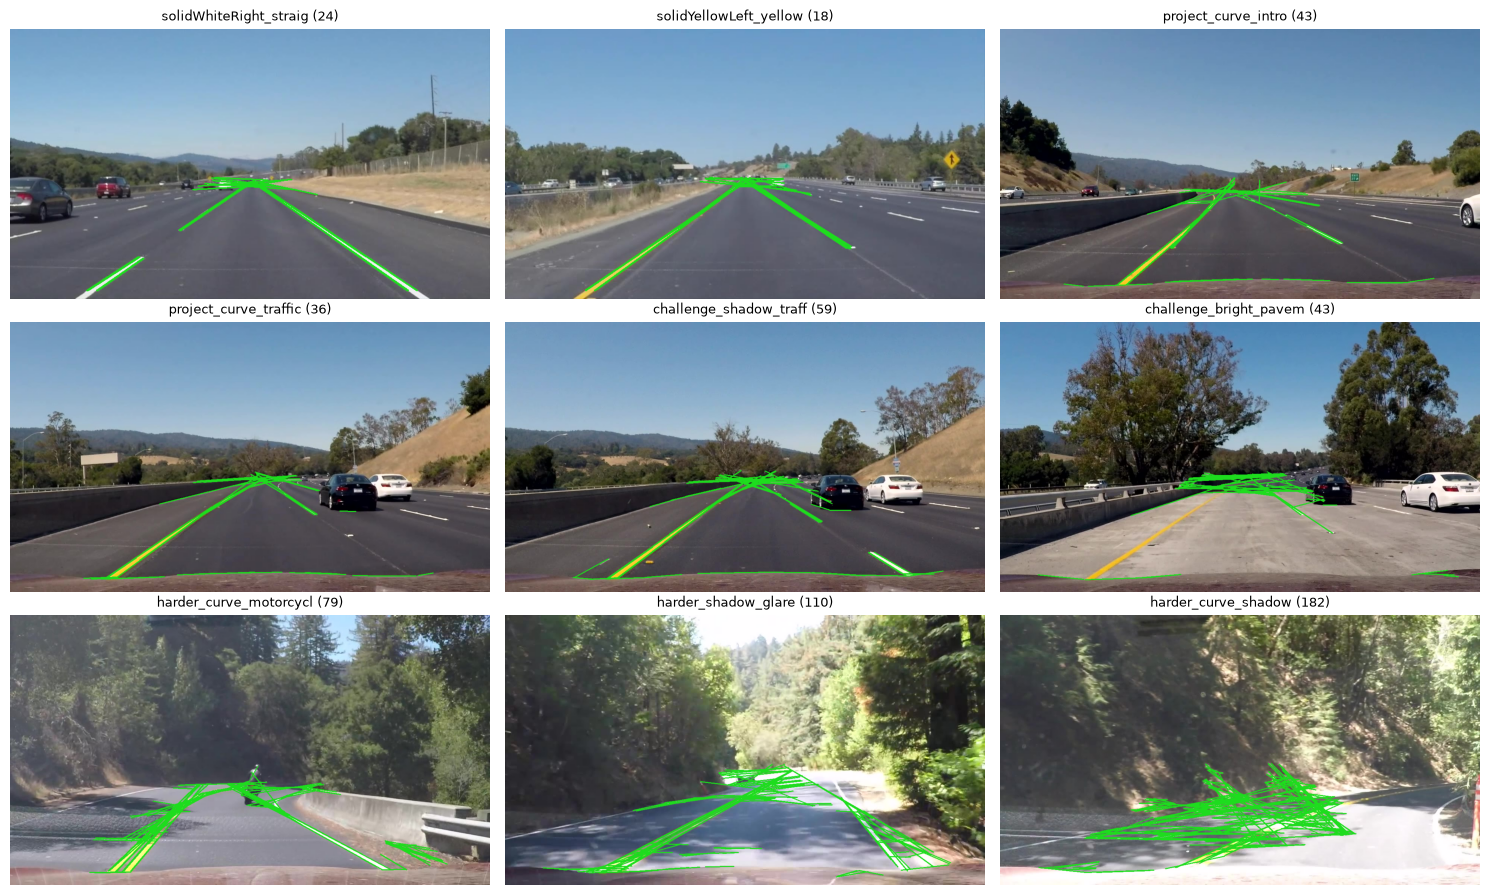

In [5]:
files=sorted(IMAGES.glob('*.jpg'))
fig,ax=plt.subplots(3,3,figsize=(15,9))
for a,p in zip(ax.flat,files):
    _,_,result,lines=pipeline(read(p.name))
    a.imshow(cv2.cvtColor(result,cv2.COLOR_BGR2RGB))
    a.set_title(p.stem[3:25]+f' ({len(lines)})',fontsize=9);a.axis('off')
plt.tight_layout();plt.show()

## 05 · 视频延伸
ZIP 内视频 videos/solidWhiteRight_8s.mp4 可作为逐帧独立检测案例；本基线尚未实现时序跟踪。